
# STRATUM — Statistical Significance and Hypothesis Testing

## Phase 3 — Supplementary Research Investigation

### Background

Previous exploratory analysis identified associations
between equipment characteristics, process stability,
material properties, and semiconductor wafer quality.

This investigation evaluates the statistical evidence
and magnitude of selected observed relationships.

### Objectives

1. Investigate the association between equipment
   identity and overall wafer quality.

2. Investigate the association between process
   stability and overall wafer quality.

3. Evaluate material-property differences across
   equipment groups.

4. Evaluate material-property differences between
   overall good-quality and bad-quality wafers.

5. Identify APC variables with statistically
   supported monotonic associations with thickness
   and sheet resistance.

### Statistical Methods

- Pearson Chi-square test of independence.
- Fisher's exact test for sparse 2x2 tables.
- Monte Carlo conditional testing for larger sparse tables.
- Cramer's V effect size.
- Kruskal-Wallis test.
- Mann-Whitney U test.
- Rank-biserial correlation effect size.
- Spearman rank correlation.
- Holm multiple-testing correction.

### Analysis Protocol

- Significance level: alpha = 0.05.
- Use the original training partition.
- Select one chronological representative wafer per lot
  for primary statistical testing.
- Retain full training observations for descriptive
  comparisons.
- Check statistical assumptions and sample sizes.
- Report effect sizes alongside p-values.
- Do not use the reserved final test partition.

### Research Limitations

The hypotheses were informed by earlier exploratory
analysis and are therefore exploratory rather than
independently preregistered confirmatory hypotheses.

Selecting one wafer per lot reduces within-lot
dependence but does not guarantee independence
across equipment, batches, or chronological periods.

Statistical association does not establish
manufacturing causality.

Overall quality labels are derived from measured
material-property quality classifications.
Associations with those properties must therefore
be interpreted as descriptive rather than
independent predictive evidence.

In [50]:

# Imports and project configuration

from pathlib import Path
import sys
import json
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import scipy
from scipy import stats

sns.set_theme(style="whitegrid")

current_dir = Path.cwd()

if (current_dir / "ml" / "data_split.py").exists():

    project_root = current_dir

elif (
    current_dir.parent / "ml" / "data_split.py"
).exists():

    project_root = current_dir.parent

else:

    raise FileNotFoundError(
        "Cannot locate STRATUM project root."
    )

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from ml.data_split import chronological_lot_split
from ml.preprocessing import get_feature_columns

ALPHA = 0.05
RANDOM_STATE = 42
N_MONTE_CARLO = 19999
MIN_CORRELATION_RECORDS = 30

print("STRATUM - Statistical Significance Testing")
print("Python version:", sys.version.split()[0])
print("SciPy version:", scipy.__version__)
print("Significance level:", ALPHA)
print("\nAll modules imported successfully!")

STRATUM - Statistical Significance Testing
Python version: 3.14.3
SciPy version: 1.18.1
Significance level: 0.05

All modules imported successfully!


## 1. Dataset and Partition Reproducibility

Verify the original dataset fingerprint and reproduce
the fixed chronological, lot-aware partitions.

Restrict statistical analysis to the original
training partition.

The final test partition remains reserved.

In [51]:

# Load and verify the dataset

csv_path = (
    project_root
    / "data"
    / "raw"
    / "apc_spc_AlCu_inputs_outputs.csv"
)

manifest_path = (
    project_root
    / "docs"
    / "split_manifest.json"
)

manifest = json.loads(
    manifest_path.read_text(encoding="utf-8")
)

current_sha256 = hashlib.sha256(
    csv_path.read_bytes()
).hexdigest()

assert (
    current_sha256 == manifest["dataset_sha256"]
), "Dataset fingerprint mismatch."

df = pd.read_csv(
    csv_path,
    sep=";",
    skiprows=1,
    low_memory=False,
)

assert df.shape == (5208, 178)

train_df, val_df, test_df, split_info = (
    chronological_lot_split(
        df,
        test_fraction=manifest["test_fraction"],
        validation_fraction=manifest[
            "validation_fraction_of_development"
        ],
    )
)

assert split_info == manifest["split_summary"]

apc_features, feature_columns = (
    get_feature_columns(df)
)

assert (
    apc_features == manifest["numeric_apc_features"]
)

print("Dataset fingerprint: VERIFIED")
print("Chronological partitions: VERIFIED")
print("APC feature schema: VERIFIED")

print("\nTraining records:", len(train_df))
print("Reserved validation records:", len(val_df))
print("Reserved test records:", len(test_df))

Dataset fingerprint: VERIFIED
Chronological partitions: VERIFIED
APC feature schema: VERIFIED

Training records: 3331
Reserved validation records: 834
Reserved test records: 1042


## 2. Statistical Analysis Population

Multiple wafer observations may belong to the same lot.

To reduce within-lot dependence, construct a primary
analysis population using the earliest eligible wafer
from each training lot.

Use chronological run time and wafer identifier
for deterministic representative selection.

The full training population is retained for
descriptive sensitivity comparisons.

This procedure does not establish complete statistical
independence between different manufacturing lots.

In [52]:

# Prepare full training analysis population

analysis_df = train_df.copy()

analysis_df["runstart"] = pd.to_datetime(
    analysis_df["runstart"],
    errors="raise",
)

required_columns = [
    "wafer_id",
    "lot",
    "equipment",
    "runstart",
    "stable_state",
    "quality_overall",
    "mean_thickness",
    "mean_resistance",
]

assert all(
    col in analysis_df.columns
    for col in required_columns
)

assert not analysis_df[
    ["wafer_id", "lot", "runstart"]
].isna().any().any()

assert analysis_df["wafer_id"].is_unique

# Verify the documented overall quality encoding

observed_quality_labels = set(
    analysis_df["quality_overall"]
    .dropna()
    .unique()
)

assert observed_quality_labels == {0, 1}, (
    "Unexpected overall quality encoding."
)

analysis_df["Overall Quality"] = (
    analysis_df["quality_overall"]
    .map({
        0: "Good",
        1: "Bad",
    })
)

analysis_df = (
    analysis_df
    .sort_values(["runstart", "wafer_id"])
    .reset_index(drop=True)
)

# Select one representative wafer per lot

lot_analysis_df = (
    analysis_df
    .drop_duplicates(
        subset="lot",
        keep="first",
    )
    .reset_index(drop=True)
)

assert lot_analysis_df["lot"].is_unique

assert len(lot_analysis_df) == (
    analysis_df["lot"].nunique()
)

population_summary = pd.DataFrame([
    {
        "Population": "Full Training",
        "Records": len(analysis_df),
        "Unique Lots": analysis_df["lot"].nunique(),
        "Equipment Groups": (
            analysis_df["equipment"].nunique()
        ),
        "Bad Quality Records": int(
            (analysis_df["quality_overall"] == 1).sum()
        ),
        "Bad Quality (%)": (
            (analysis_df["quality_overall"] == 1).mean()
            * 100
        ),
    },
    {
        "Population": "One Wafer per Lot",
        "Records": len(lot_analysis_df),
        "Unique Lots": lot_analysis_df["lot"].nunique(),
        "Equipment Groups": (
            lot_analysis_df["equipment"].nunique()
        ),
        "Bad Quality Records": int(
            (
                lot_analysis_df["quality_overall"] == 1
            ).sum()
        ),
        "Bad Quality (%)": (
            (
                lot_analysis_df["quality_overall"] == 1
            ).mean() * 100
        ),
    },
])

display(
    population_summary.round(4)
)

print("\nPrimary statistical population:")
print("Records:", len(lot_analysis_df))

print("\nObserved stability categories:")

display(
    lot_analysis_df["stable_state"]
    .value_counts(dropna=False)
)

,Population,Records,Unique Lots,Equipment Groups,Bad Quality Records,Bad Quality (%)
0,Full Training,3331,1874,16,272,8.1657
1,One Wafer per Lot,1874,1874,16,164,8.7513



Primary statistical population:
Records: 1874

Observed stability categories:


stable_state
1    1456
0     418
Name: count, dtype: int64

In [53]:

# Investigate remaining batch dependence

batch_dependency_summary = (
    lot_analysis_df
    .dropna(subset=["bat_id"])
    .groupby("bat_id")
    .agg(
        Representative_Wafers=("wafer_id", "count"),
        Unique_Lots=("lot", "nunique"),
    )
)

shared_batches = batch_dependency_summary.loc[
    batch_dependency_summary["Unique_Lots"] > 1
]

print(
    "Unique batches in representative population:",
    len(batch_dependency_summary)
)

print(
    "Batches containing multiple represented lots:",
    len(shared_batches)
)

print(
    "Representative wafers with missing batch ID:",
    int(lot_analysis_df["bat_id"].isna().sum())
)

print(
    "Largest represented lot count within a batch:",
    (
        int(
            batch_dependency_summary["Unique_Lots"].max()
        )
        if not batch_dependency_summary.empty
        else 0
    )
)

display(
    batch_dependency_summary
    .sort_values(
        "Unique_Lots",
        ascending=False,
    )
    .head(10)
)

Unique batches in representative population: 1874
Batches containing multiple represented lots: 0
Representative wafers with missing batch ID: 0
Largest represented lot count within a batch: 1


,Representative_Wafers,Unique_Lots
bat_id,,
13266763,1,1
13274131,1,1
13345497,1,1
13389981,1,1
13397881,1,1
13431376,1,1
13520009,1,1
13520482,1,1
13587564,1,1


## 3. Statistical Helper Functions

Implement Holm-adjusted p-values, categorical
association testing and effect-size calculations.

Check expected cell frequencies before selecting
the categorical test procedure.

Use Monte Carlo conditional testing for larger
sparse contingency tables.

These methods address multiple testing and sparse
frequencies but cannot eliminate dependence
between manufacturing observations.

In [54]:

# Holm multiple-testing correction

def holm_adjust(p_values):

    p_values = np.asarray(
        p_values,
        dtype=float,
    )

    if p_values.ndim != 1:
        raise ValueError("Expected 1D p-values.")

    if len(p_values) == 0:
        return p_values.copy()

    if not np.isfinite(p_values).all():
        raise ValueError("Non-finite p-values detected.")

    if (
        (p_values < 0).any()
        or (p_values > 1).any()
    ):
        raise ValueError("Invalid p-value range.")

    m = len(p_values)

    order = np.argsort(p_values)

    sorted_p = p_values[order]

    adjusted_sorted = np.maximum.accumulate(
        (m - np.arange(m)) * sorted_p
    )

    adjusted_sorted = np.clip(
        adjusted_sorted,
        0,
        1,
    )

    adjusted = np.empty_like(adjusted_sorted)

    adjusted[order] = adjusted_sorted

    return adjusted


# Verify the correction implementation

np.testing.assert_allclose(
    holm_adjust([0.01, 0.04, 0.03]),
    [0.03, 0.06, 0.06],
)

print("Holm correction verification: PASSED")

Holm correction verification: PASSED


In [55]:

# Categorical association helpers

def calculate_cramers_v(table):

    observed = np.asarray(
        table,
        dtype=float,
    )

    chi2, _, _, _ = stats.chi2_contingency(
        observed,
        correction=False,
    )

    n = observed.sum()

    rows, columns = observed.shape

    denominator = (
        n * min(rows - 1, columns - 1)
    )

    if denominator <= 0:
        raise ValueError(
            "Cramer's V requires at least two "
            "nonempty rows and columns."
        )

    return float(
        np.sqrt(chi2 / denominator)
    )


def categorical_association_test(
    data,
    predictor,
    outcome,
    hypothesis_id,
):

    subset = data[
        [predictor, outcome]
    ].dropna()

    table = pd.crosstab(
        subset[predictor],
        subset[outcome],
    )

    observed = table.to_numpy()

    if min(observed.shape) < 2:

        raise ValueError(
            f"Insufficient categories for {hypothesis_id}"
        )

    chi2, chi_p, dof, expected = (
        stats.chi2_contingency(
            observed,
            correction=False,
        )
    )

    expected_below_five_pct = (
        (expected < 5).mean() * 100
    )

    expected_minimum = float(
        expected.min()
    )

    # Common screening rule for the Pearson approximation

    chi_square_conditions_met = (
        expected_minimum >= 1
        and expected_below_five_pct <= 20
    )

    if chi_square_conditions_met:

        test_name = "Pearson Chi-square"

        p_value = float(chi_p)

        test_statistic = float(chi2)

        statistic_name = "Chi-square"

    elif observed.shape == (2, 2):

        fisher_result = stats.fisher_exact(
            observed,
            alternative="two-sided",
        )

        test_name = "Fisher exact"

        p_value = float(
            fisher_result.pvalue
        )

        odds_ratio = float(
            fisher_result.statistic
        )

        test_statistic = (
            odds_ratio
            if np.isfinite(odds_ratio)
            else None
        )

        statistic_name = "Odds ratio"

    else:

        # Simulate contingency tables under independence,
        # conditional on the observed row and column totals.

        row_totals = observed.sum(axis=1)

        column_totals = observed.sum(axis=0)

        rng = np.random.default_rng(
            RANDOM_STATE
        )

        simulated_tables = stats.random_table.rvs(
            row_totals,
            column_totals,
            size=N_MONTE_CARLO,
            random_state=rng,
        )

        simulated_statistics = (
            (
                (simulated_tables - expected) ** 2
            ) / expected
        ).sum(axis=(1, 2))

        extreme_count = int(
            (
                simulated_statistics
                >= chi2 - 1e-12
            ).sum()
        )

        p_value = (
            extreme_count + 1
        ) / (
            N_MONTE_CARLO + 1
        )

        test_name = (
            "Monte Carlo conditional Chi-square"
        )

        test_statistic = float(chi2)

        statistic_name = "Chi-square"

    result = {
        "Hypothesis": hypothesis_id,
        "Predictor": predictor,
        "Outcome": outcome,
        "Test": test_name,
        "Statistic Name": statistic_name,
        "Statistic": test_statistic,
        "Pearson Chi-square": float(chi2),
        "Degrees of Freedom": int(dof),
        "Records": len(subset),
        "Minimum Expected Count": expected_minimum,
        "Expected Cells Below 5 (%)": float(
            expected_below_five_pct
        ),
        "Chi-square Conditions Met": bool(
            chi_square_conditions_met
        ),
        "P-value": float(p_value),
        "Effect Size Name": "Cramer's V",
        "Effect Size": calculate_cramers_v(table),
    }

    expected_df = pd.DataFrame(
        expected,
        index=table.index,
        columns=table.columns,
    )

    return result, table, expected_df


print("Categorical statistical helpers ready.")

Categorical statistical helpers ready.


## 4. Hypothesis H1 — Equipment and Overall Quality

### Null Hypothesis

Equipment identity and overall wafer quality
are statistically independent.

### Alternative Hypothesis

Equipment identity and overall wafer quality
are statistically associated.

### Method

Construct an equipment-by-quality contingency table.

Evaluate expected frequencies and select an
appropriate categorical significance test.

Report Cramer's V to quantify association strength.

In [56]:

# H1: Equipment vs overall quality

h1_result, equipment_quality_table, equipment_expected = (
    categorical_association_test(
        data=lot_analysis_df,
        predictor="equipment",
        outcome="Overall Quality",
        hypothesis_id="H1",
    )
)

print("Observed frequencies:")

display(equipment_quality_table)

print("\nExpected frequencies under independence:")

display(
    equipment_expected.round(3)
)

print("\nStatistical test results:")

display(
    pd.Series(h1_result).to_frame("Result")
)

Observed frequencies:


Overall Quality,Bad,Good
equipment,,
equipment_1,5,45
equipment_10,1,26
equipment_11,8,256
equipment_12,2,116
equipment_13,37,258
equipment_14,1,71
equipment_15,34,227
equipment_16,0,50
equipment_2,11,62



Expected frequencies under independence:


Overall Quality,Bad,Good
equipment,,
equipment_1,4.376,45.624
equipment_10,2.363,24.637
equipment_11,23.104,240.896
equipment_12,10.327,107.673
equipment_13,25.816,269.184
equipment_14,6.301,65.699
equipment_15,22.841,238.159
equipment_16,4.376,45.624
equipment_2,6.388,66.612



Statistical test results:


,Result
Hypothesis,H1
Predictor,equipment
Outcome,Overall Quality
Test,Pearson Chi-square
Statistic Name,Chi-square
Statistic,57.724574
Pearson Chi-square,57.724574
Degrees of Freedom,15
Records,1874
Minimum Expected Count,2.275347


Overall Quality,Good,Bad,Records,Bad Quality (%)
equipment,,,,
equipment_3,62,11,73,15.0685
equipment_2,62,11,73,15.0685
equipment_8,57,10,67,14.9254
equipment_15,227,34,261,13.0268
equipment_13,258,37,295,12.5424
equipment_7,80,11,91,12.0879
equipment_1,45,5,50,10.0000
equipment_9,269,27,296,9.1216
equipment_6,51,5,56,8.9286


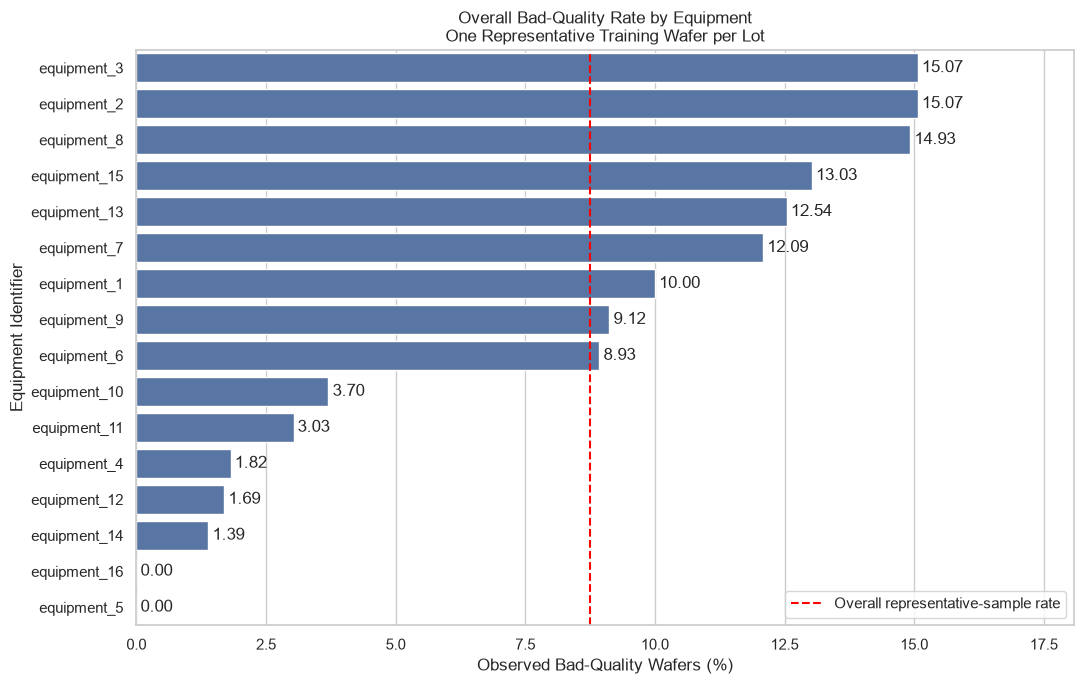

In [57]:

# Equipment-specific observed quality rates

equipment_quality_rates = (
    equipment_quality_table
    .reindex(
        columns=["Good", "Bad"],
        fill_value=0,
    )
    .copy()
)

equipment_quality_rates["Records"] = (
    equipment_quality_rates["Good"]
    + equipment_quality_rates["Bad"]
)

equipment_quality_rates["Bad Quality (%)"] = (
    equipment_quality_rates["Bad"]
    / equipment_quality_rates["Records"]
    * 100
)

equipment_quality_rates = (
    equipment_quality_rates
    .sort_values(
        "Bad Quality (%)",
        ascending=False,
    )
)

display(
    equipment_quality_rates.round(4)
)

overall_bad_rate = (
    (
        lot_analysis_df["quality_overall"] == 1
    ).mean() * 100
)

plt.figure(figsize=(11, 7))

ax = sns.barplot(
    data=equipment_quality_rates.reset_index(),
    x="Bad Quality (%)",
    y="equipment",
)

ax.axvline(
    overall_bad_rate,
    color="red",
    linestyle="--",
    label="Overall representative-sample rate",
)

ax.bar_label(
    ax.containers[0],
    fmt="%.2f",
    padding=3,
)

plt.xlim(
    0,
    max(
        overall_bad_rate,
        equipment_quality_rates[
            "Bad Quality (%)"
        ].max(),
    ) * 1.2,
)

plt.title(
    "Overall Bad-Quality Rate by Equipment\n"
    "One Representative Training Wafer per Lot"
)

plt.xlabel("Observed Bad-Quality Wafers (%)")
plt.ylabel("Equipment Identifier")

plt.legend()
plt.tight_layout()
plt.show()

Overall Quality,Bad,Good
equipment,,
equipment_1,0.298,-0.092
equipment_10,-0.887,0.275
equipment_11,-3.142,0.973
equipment_12,-2.591,0.802
equipment_13,2.201,-0.682
equipment_14,-2.112,0.654
equipment_15,2.335,-0.723
equipment_16,-2.092,0.648
equipment_2,1.825,-0.565


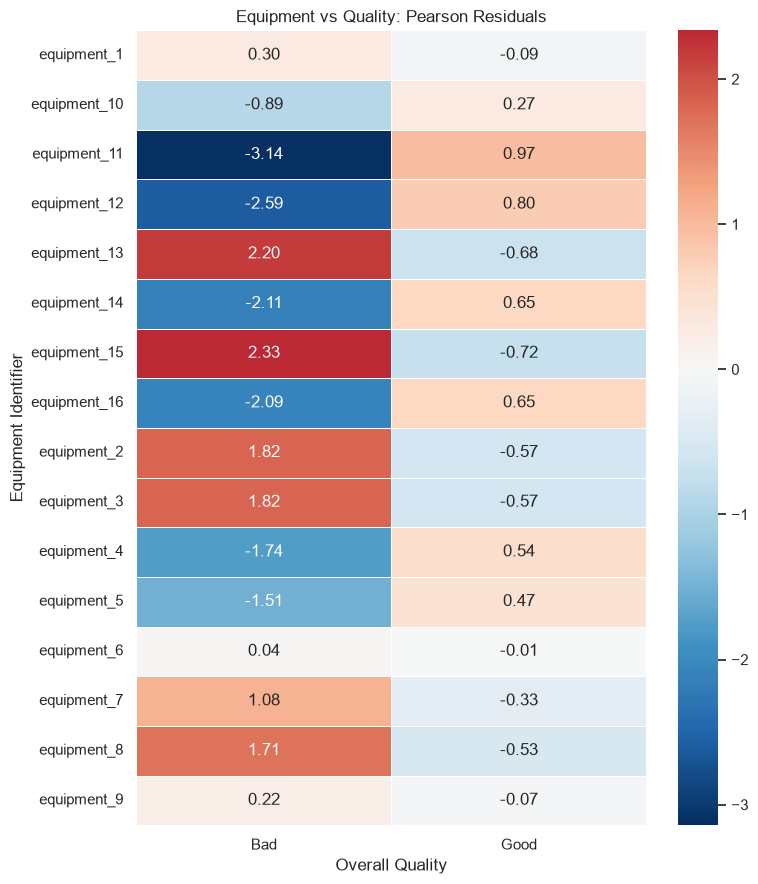

In [58]:

# Pearson residuals for the contingency table

equipment_pearson_residuals = (
    equipment_quality_table - equipment_expected
) / np.sqrt(equipment_expected)

display(
    equipment_pearson_residuals.round(3)
)

plt.figure(figsize=(8, 9))

sns.heatmap(
    equipment_pearson_residuals,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
)

plt.title(
    "Equipment vs Quality: Pearson Residuals"
)

plt.xlabel("Overall Quality")
plt.ylabel("Equipment Identifier")

plt.tight_layout()
plt.show()

## 5. Hypothesis H2 — Process Stability and Overall Quality

### Null Hypothesis

Process stability and overall wafer quality
are statistically independent.

### Alternative Hypothesis

Process stability and overall wafer quality
are statistically associated.

### Method

Construct a stability-by-quality contingency table.

Apply the categorical association test appropriate
for the observed expected frequencies.

Report statistical significance and Cramer's V.

Process stability is a dataset-defined indicator.
It must not be interpreted as a comprehensive
assessment of all manufacturing process conditions.

In [59]:

# H2: Process stability vs overall quality

h2_result, stability_quality_table, stability_expected = (
    categorical_association_test(
        data=lot_analysis_df,
        predictor="stable_state",
        outcome="Overall Quality",
        hypothesis_id="H2",
    )
)

print("Observed frequencies:")

display(stability_quality_table)

print("\nExpected frequencies:")

display(
    stability_expected.round(3)
)

print("\nStatistical test results:")

display(
    pd.Series(h2_result).to_frame("Result")
)

Observed frequencies:


Overall Quality,Bad,Good
stable_state,,
0,43,375
1,121,1335



Expected frequencies:


Overall Quality,Bad,Good
stable_state,,
0,36.581,381.419
1,127.419,1328.581



Statistical test results:


,Result
Hypothesis,H2
Predictor,stable_state
Outcome,Overall Quality
Test,Pearson Chi-square
Statistic Name,Chi-square
Statistic,1.588998
Pearson Chi-square,1.588998
Degrees of Freedom,1
Records,1874
Minimum Expected Count,36.580576


Overall Quality,Good,Bad,Records,Bad Quality (%)
stable_state,,,,
0,375,43,418,10.2871
1,1335,121,1456,8.3104


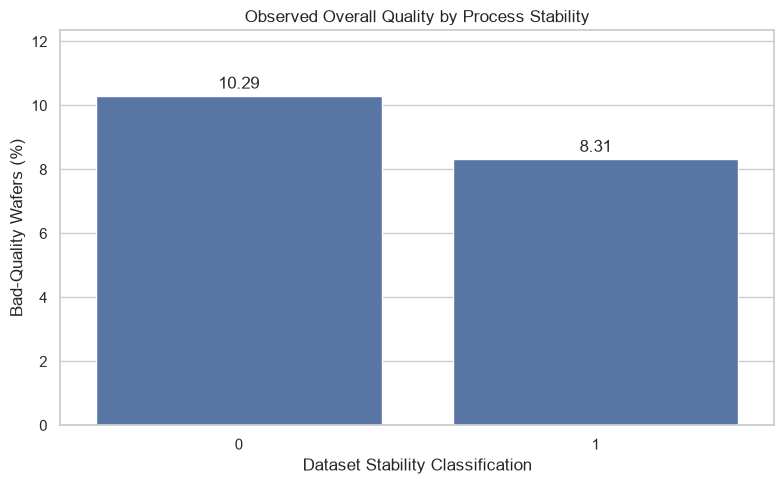

In [60]:

# Quality rates by stability category

stability_quality_rates = (
    stability_quality_table
    .reindex(
        columns=["Good", "Bad"],
        fill_value=0,
    )
    .copy()
)

stability_quality_rates["Records"] = (
    stability_quality_rates["Good"]
    + stability_quality_rates["Bad"]
)

stability_quality_rates["Bad Quality (%)"] = (
    stability_quality_rates["Bad"]
    / stability_quality_rates["Records"]
    * 100
)

display(
    stability_quality_rates.round(4)
)

stability_plot_data = (
    stability_quality_rates
    .reset_index()
)

stability_plot_data["stable_state"] = (
    stability_plot_data["stable_state"]
    .astype(str)
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=stability_plot_data,
    x="stable_state",
    y="Bad Quality (%)",
)

ax.bar_label(
    ax.containers[0],
    fmt="%.2f",
    padding=3,
)

plt.ylim(
    0,
    max(
        1.0,
        stability_plot_data[
            "Bad Quality (%)"
        ].max(),
    ) * 1.2,
)

plt.title(
    "Observed Overall Quality by Process Stability"
)

plt.xlabel("Dataset Stability Classification")
plt.ylabel("Bad-Quality Wafers (%)")

plt.tight_layout()
plt.show()

## 6. Hypothesis H3 — Material Properties Across Equipment

### Hypotheses

H3a: Mean film thickness distributions differ
across manufacturing equipment identifiers.

H3b: Mean sheet-resistance distributions differ
across manufacturing equipment identifiers.

The null hypothesis for each test is equality
of the corresponding group distributions.

### Method

Use the Kruskal-Wallis rank-based omnibus test.

Report the H statistic, degrees of freedom,
p-value, and rank-based epsilon-squared estimate.

A significant omnibus result does not identify
which particular equipment pairs differ.

No causal equipment effects are inferred.

In [61]:

# H3: Kruskal-Wallis equipment comparison

def equipment_kruskal_test(
    data,
    target,
    hypothesis_id,
):

    subset = (
        data[["equipment", target]]
        .dropna()
    )

    groups = [
        group[target].to_numpy(dtype=float)

        for _, group in subset.groupby("equipment")
    ]

    groups = [
        values[np.isfinite(values)]
        for values in groups
    ]

    group_sizes = [
        len(values)
        for values in groups
    ]

    if len(groups) < 2:

        raise ValueError(
            "At least two equipment groups required."
        )

    if min(group_sizes) < 5:

        raise ValueError(
            "Insufficient group size for the planned "
            "Kruskal-Wallis approximation."
        )

    statistic, p_value = stats.kruskal(
        *groups
    )

    n = sum(group_sizes)

    k = len(groups)

    # Rank-based epsilon-squared effect-size estimate

    epsilon_squared = max(
        0.0,
        (statistic - k + 1) / (n - k),
    )

    return {
        "Hypothesis": hypothesis_id,
        "Predictor": "equipment",
        "Outcome": target,
        "Test": "Kruskal-Wallis",
        "Statistic Name": "H",
        "Statistic": float(statistic),
        "Degrees of Freedom": k - 1,
        "Records": n,
        "Groups": k,
        "Minimum Group Size": min(group_sizes),
        "P-value": float(p_value),
        "Effect Size Name": (
            "Rank-based epsilon-squared"
        ),
        "Effect Size": float(epsilon_squared),
    }


h3a_result = equipment_kruskal_test(
    data=lot_analysis_df,
    target="mean_thickness",
    hypothesis_id="H3a",
)

h3b_result = equipment_kruskal_test(
    data=lot_analysis_df,
    target="mean_resistance",
    hypothesis_id="H3b",
)

display(
    pd.DataFrame([
        h3a_result,
        h3b_result,
    ]).T
)

,0,1
Hypothesis,H3a,H3b
Predictor,equipment,equipment
Outcome,mean_thickness,mean_resistance
Test,Kruskal-Wallis,Kruskal-Wallis
Statistic Name,H,H
Statistic,190.533446,159.893227
Degrees of Freedom,15,15
Records,1874,1874
Groups,16,16
Minimum Group Size,26,26


In [62]:

# Equipment-level material-property statistics

equipment_material_summary = (
    lot_analysis_df
    .groupby("equipment")
    .agg(
        Records=("wafer_id", "count"),

        Thickness_Mean=(
            "mean_thickness", "mean"
        ),

        Thickness_Median=(
            "mean_thickness", "median"
        ),

        Thickness_Std=(
            "mean_thickness", "std"
        ),

        Resistance_Mean=(
            "mean_resistance", "mean"
        ),

        Resistance_Median=(
            "mean_resistance", "median"
        ),

        Resistance_Std=(
            "mean_resistance", "std"
        ),
    )
)

display(
    equipment_material_summary.round(8)
)

,Records,Thickness_Mean,Thickness_Median,Thickness_Std,Resistance_Mean,Resistance_Median,Resistance_Std
equipment,,,,,,,
equipment_1,50,150.459623,149.843606,2.959494,0.002929,0.002938,0.000061
equipment_10,27,152.607265,152.830733,2.292067,0.002907,0.002887,0.000075
equipment_11,264,152.738861,152.900023,2.799291,0.002886,0.002883,0.000055
equipment_12,118,150.131505,149.386021,2.105569,0.002938,0.002950,0.000044
equipment_13,295,152.227541,152.395195,1.953092,0.002892,0.002887,0.000042
equipment_14,72,150.702385,151.204214,2.745955,0.002927,0.002912,0.000056
equipment_15,261,152.464695,152.597666,2.664786,0.002892,0.002888,0.000054
equipment_16,50,152.249937,152.469434,2.099291,0.002901,0.002895,0.000044
equipment_2,73,151.867672,151.925461,2.371564,0.002899,0.002896,0.000050


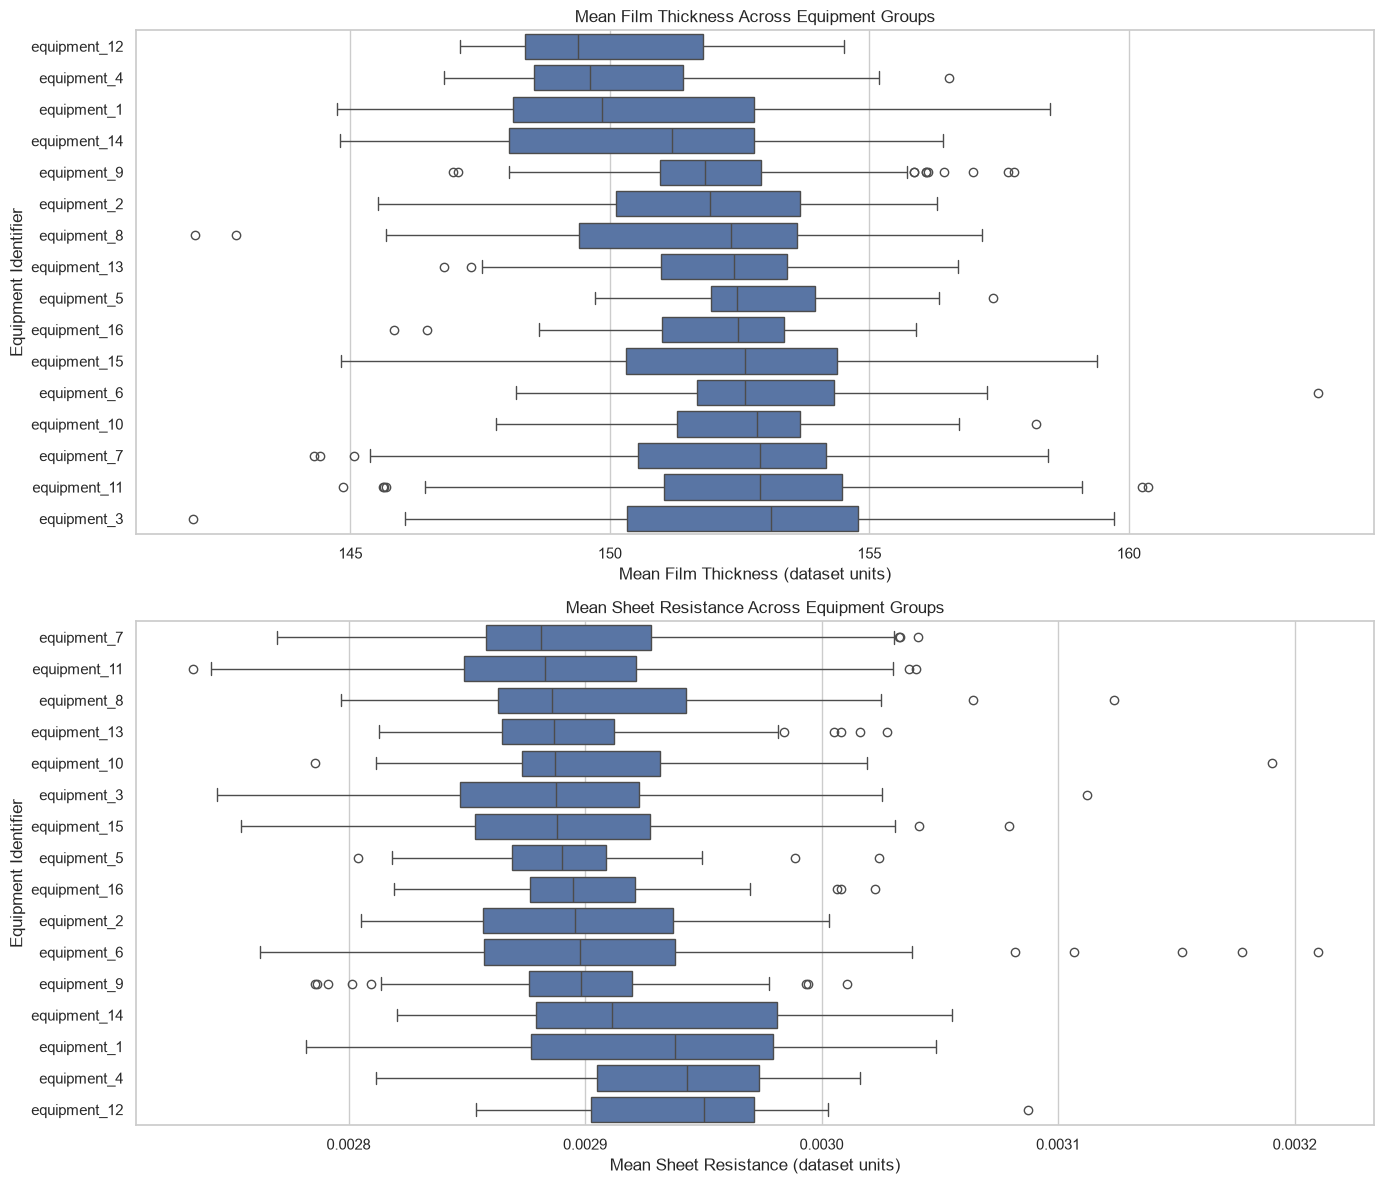

In [63]:

# Material-property distributions across equipment

fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 12),
)

for ax, target, label in [
    (
        axes[0],
        "mean_thickness",
        "Mean Film Thickness",
    ),
    (
        axes[1],
        "mean_resistance",
        "Mean Sheet Resistance",
    ),
]:

    equipment_order = (
        lot_analysis_df
        .groupby("equipment")[target]
        .median()
        .sort_values()
        .index
    )

    sns.boxplot(
        data=lot_analysis_df,
        x=target,
        y="equipment",
        order=equipment_order,
        ax=ax,
    )

    ax.set_title(
        f"{label} Across Equipment Groups"
    )

    ax.set_xlabel(
        f"{label} (dataset units)"
    )

    ax.set_ylabel("Equipment Identifier")

plt.tight_layout()
plt.show()

## 7. Hypothesis H4 — Material Properties and Overall Quality

### Hypotheses

H4a: Measured mean film thickness distributions
differ between overall good-quality and
bad-quality wafer observations.

H4b: Measured mean sheet-resistance distributions
differ between overall good-quality and
bad-quality wafer observations.

### Method

Apply the two-sided Mann-Whitney U test.

Report group sample sizes, group medians,
test statistics, p-values, and rank-biserial
correlation effect sizes.

### Interpretation Limitation

Overall quality is derived from material-property
quality classifications.

The analysis therefore characterises relationships
within the dataset rather than independently
validating prospective quality prediction.

In [64]:

# H4: Mann-Whitney material-property comparison

def quality_mannwhitney_test(
    data,
    target,
    hypothesis_id,
):

    subset = data[
        ["Overall Quality", target]
    ].dropna()

    bad = subset.loc[
        subset["Overall Quality"] == "Bad",
        target,
    ].to_numpy(dtype=float)

    good = subset.loc[
        subset["Overall Quality"] == "Good",
        target,
    ].to_numpy(dtype=float)

    bad = bad[np.isfinite(bad)]
    good = good[np.isfinite(good)]

    if min(len(bad), len(good)) < 5:

        raise ValueError(
            "Insufficient quality-group observations."
        )

    statistic, p_value = stats.mannwhitneyu(
        bad,
        good,
        alternative="two-sided",
        method="asymptotic",
    )

    # Direction:
    # positive = bad-quality values tend to be higher
    # negative = bad-quality values tend to be lower

    rank_biserial = (
        2 * statistic / (len(bad) * len(good))
        - 1
    )

    return {
        "Hypothesis": hypothesis_id,
        "Predictor": "Overall Quality",
        "Outcome": target,
        "Test": "Mann-Whitney U",
        "Statistic Name": "U",
        "Statistic": float(statistic),
        "Records": len(bad) + len(good),
        "Bad Quality Records": len(bad),
        "Good Quality Records": len(good),
        "Bad Group Median": float(
            np.median(bad)
        ),
        "Good Group Median": float(
            np.median(good)
        ),
        "P-value": float(p_value),
        "Effect Size Name": (
            "Rank-biserial correlation"
        ),
        "Effect Size": float(rank_biserial),
    }


h4a_result = quality_mannwhitney_test(
    data=lot_analysis_df,
    target="mean_thickness",
    hypothesis_id="H4a",
)

h4b_result = quality_mannwhitney_test(
    data=lot_analysis_df,
    target="mean_resistance",
    hypothesis_id="H4b",
)

display(
    pd.DataFrame([
        h4a_result,
        h4b_result,
    ]).T
)

,0,1
Hypothesis,H4a,H4b
Predictor,Overall Quality,Overall Quality
Outcome,mean_thickness,mean_resistance
Test,Mann-Whitney U,Mann-Whitney U
Statistic Name,U,U
Statistic,150028.0,95425.5
Records,1874,1874
Bad Quality Records,164,164
Good Quality Records,1710,1710
Bad Group Median,152.513978,0.002864


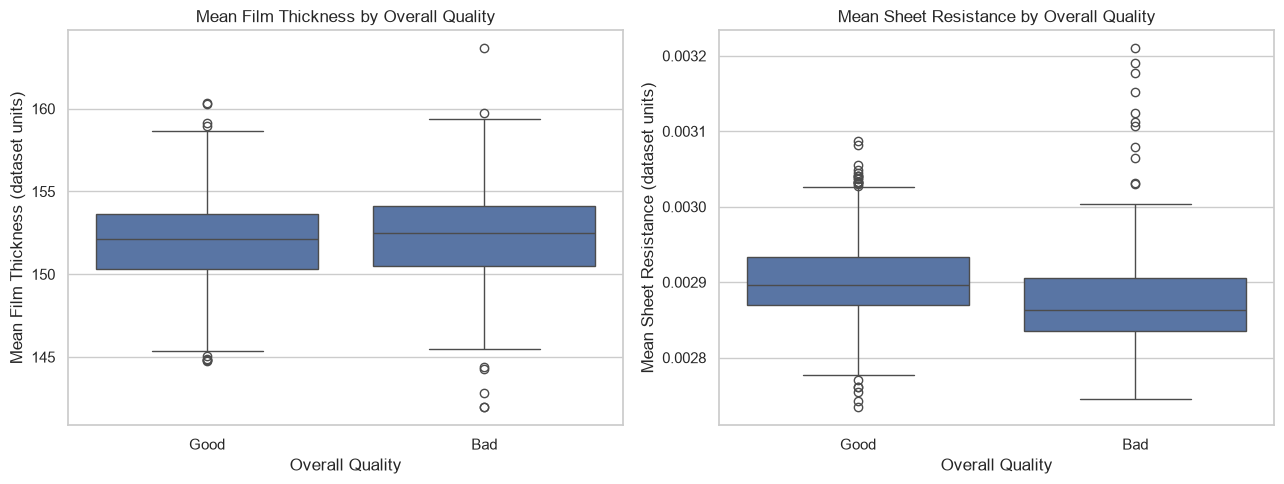

In [65]:

# Measured material properties by overall quality

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
)

for ax, target, label in [
    (
        axes[0],
        "mean_thickness",
        "Mean Film Thickness",
    ),
    (
        axes[1],
        "mean_resistance",
        "Mean Sheet Resistance",
    ),
]:

    sns.boxplot(
        data=lot_analysis_df,
        x="Overall Quality",
        y=target,
        order=["Good", "Bad"],
        ax=ax,
    )

    ax.set_title(
        f"{label} by Overall Quality"
    )

    ax.set_xlabel("Overall Quality")

    ax.set_ylabel(
        f"{label} (dataset units)"
    )

plt.tight_layout()
plt.show()

## 8. Primary Hypothesis Test Summary

Consolidate the six primary statistical tests.

Apply Holm multiple-testing correction across
the complete primary hypothesis family.

Report raw and adjusted p-values, effect sizes,
and significance decisions at alpha = 0.05.

A failure to reject the null hypothesis is not
proof that no association or difference exists.

Statistical significance does not independently
establish practical manufacturing relevance.

In [66]:

# Consolidate primary hypothesis testing

primary_results = [
    h1_result,
    h2_result,
    h3a_result,
    h3b_result,
    h4a_result,
    h4b_result,
]

primary_results_df = pd.DataFrame(
    primary_results
)

primary_results_df["Holm Adjusted P-value"] = (
    holm_adjust(
        primary_results_df["P-value"].to_numpy()
    )
)

primary_results_df["Significant"] = (
    primary_results_df["Holm Adjusted P-value"]
    < ALPHA
)

primary_results_df["Decision"] = np.where(
    primary_results_df["Significant"],
    "Reject H0",
    "Fail to Reject H0",
)

primary_summary_columns = [
    "Hypothesis",
    "Predictor",
    "Outcome",
    "Test",
    "Records",
    "Statistic",
    "P-value",
    "Holm Adjusted P-value",
    "Effect Size Name",
    "Effect Size",
    "Decision",
]

display_df = primary_results_df[
    primary_summary_columns
].copy()

display_df["Statistic"] = (
    display_df["Statistic"].map("{:.6f}".format)
)

display_df["P-value"] = (
    display_df["P-value"].map("{:.4e}".format)
)

display_df["Holm Adjusted P-value"] = (
    display_df["Holm Adjusted P-value"]
    .map("{:.4e}".format)
)

display_df["Effect Size"] = (
    display_df["Effect Size"].map("{:.6f}".format)
)

display(display_df)

print(
    "Total primary hypotheses:",
    len(primary_results_df)
)

print(
    "Significant after Holm correction:",
    int(primary_results_df["Significant"].sum())
)

print(
    "Not significant after Holm correction:",
    int(
        (~primary_results_df["Significant"]).sum()
    )
)

,Hypothesis,Predictor,Outcome,Test,Records,Statistic,P-value,Holm Adjusted P-value,Effect Size Name,Effect Size,Decision
0,H1,equipment,Overall Quality,Pearson Chi-square,1874,57.724574,6.1806e-07,1.8542e-06,Cramer's V,0.175507,Reject H0
1,H2,stable_state,Overall Quality,Pearson Chi-square,1874,1.588998,2.0747e-01,2.7690e-01,Cramer's V,0.029119,Fail to Reject H0
2,H3a,equipment,mean_thickness,Kruskal-Wallis,1874,190.533446,1.7681e-32,1.0609e-31,Rank-based epsilon-squared,0.094474,Reject H0
3,H3b,equipment,mean_resistance,Kruskal-Wallis,1874,159.893227,2.5823e-26,1.2912e-25,Rank-based epsilon-squared,0.077983,Reject H0
4,H4a,Overall Quality,mean_thickness,Mann-Whitney U,1874,150028.000000,1.3845e-01,2.7690e-01,Rank-biserial correlation,0.069947,Fail to Reject H0
5,H4b,Overall Quality,mean_resistance,Mann-Whitney U,1874,95425.500000,1.3157e-11,5.2627e-11,Rank-biserial correlation,-0.319459,Reject H0


Total primary hypotheses: 6
Significant after Holm correction: 4
Not significant after Holm correction: 2


## 9. Hypothesis H5 — APC Sensor Correlation Significance

Evaluate Spearman rank correlations between
all candidate APC process variables and:

- Mean film thickness.
- Mean sheet resistance.

For each sensor-target pair:

1. Retain complete finite observation pairs.
2. Require at least 30 usable records.
3. Exclude constant variables.
4. Calculate Spearman rho and a two-sided p-value.
5. Record the number and proportion of usable records.
6. Apply Holm correction across all tested pairs.

The analysis is exploratory and univariate.

Correlation does not establish causality or
incremental predictive value.

Equipment confounding, temporal dependence,
correlated sensors and selective missingness
may influence the observed associations.

In [67]:

# H5: APC sensor Spearman correlation significance

correlation_results = []

skipped_correlations = []

correlation_targets = [
    "mean_thickness",
    "mean_resistance",
]

for target in correlation_targets:

    for feature in apc_features:

        pair = lot_analysis_df[
            [feature, target]
        ].replace(
            [np.inf, -np.inf],
            np.nan,
        ).dropna()

        n_complete = len(pair)

        if n_complete < MIN_CORRELATION_RECORDS:

            skipped_correlations.append({
                "Feature": feature,
                "Target": target,
                "Records": n_complete,
                "Reason": "Insufficient complete pairs",
            })

            continue

        if (
            pair[feature].nunique() < 2
            or pair[target].nunique() < 2
        ):

            skipped_correlations.append({
                "Feature": feature,
                "Target": target,
                "Records": n_complete,
                "Reason": "Constant variable",
            })

            continue

        rho, p_value = stats.spearmanr(
            pair[feature],
            pair[target],
            alternative="two-sided",
        )

        if not (
            np.isfinite(rho)
            and np.isfinite(p_value)
        ):

            skipped_correlations.append({
                "Feature": feature,
                "Target": target,
                "Records": n_complete,
                "Reason": "Non-finite statistic",
            })

            continue

        correlation_results.append({
            "Feature": feature,
            "Target": target,
            "Records": n_complete,

            "Usable Records (%)": (
                n_complete
                / len(lot_analysis_df)
                * 100
            ),

            "Spearman Rho": float(rho),

            "Absolute Rho": float(abs(rho)),

            "P-value": float(p_value),
        })

correlation_results_df = pd.DataFrame(
    correlation_results
)

assert not correlation_results_df.empty

correlation_results_df[
    "Holm Adjusted P-value"
] = holm_adjust(
    correlation_results_df[
        "P-value"
    ].to_numpy()
)

correlation_results_df["Significant"] = (
    correlation_results_df[
        "Holm Adjusted P-value"
    ] < ALPHA
)

correlation_results_df = (
    correlation_results_df
    .sort_values(
        ["Target", "Absolute Rho"],
        ascending=[True, False],
    )
    .reset_index(drop=True)
)

skipped_correlations_df = pd.DataFrame(
    skipped_correlations
)

print(
    "Candidate sensor-target pairs:",
    len(apc_features) * len(correlation_targets)
)

print(
    "Successfully tested pairs:",
    len(correlation_results_df)
)

print(
    "Skipped pairs:",
    len(skipped_correlations_df)
)

print(
    "Significant before correction:",
    int(
        (
            correlation_results_df["P-value"] < ALPHA
        ).sum()
    )
)

print(
    "Significant after Holm correction:",
    int(
        correlation_results_df["Significant"].sum()
    )
)

Candidate sensor-target pairs: 220
Successfully tested pairs: 216
Skipped pairs: 4
Significant before correction: 133
Significant after Holm correction: 95


In [68]:

# Summarise sensor significance by prediction target

correlation_summary = (
    correlation_results_df
    .groupby("Target")
    .agg(
        Tested_Features=("Feature", "count"),

        Significant_Features=(
            "Significant", "sum"
        ),

        Maximum_Absolute_Rho=(
            "Absolute Rho", "max"
        ),

        Median_Absolute_Rho=(
            "Absolute Rho", "median"
        ),
    )
)

display(
    correlation_summary.round(6)
)

for target in correlation_targets:

    print(f"\nTop 15 correlations: {target}")

    target_results = (
        correlation_results_df.loc[
            correlation_results_df["Target"]
            == target
        ]
        .sort_values(
            "Absolute Rho",
            ascending=False,
        )
        .head(15)
    )

    formatted_results = target_results.copy()

    formatting = {
        "Usable Records (%)": "{:.2f}",
        "Spearman Rho": "{:.6f}",
        "Absolute Rho": "{:.6f}",
        "P-value": "{:.4e}",
        "Holm Adjusted P-value": "{:.4e}",
    }

    for column, fmt in formatting.items():
        formatted_results[column] = (
            formatted_results[column].map(fmt.format)
        )

    display(formatted_results)

if not skipped_correlations_df.empty:

    print("\nSkipped sensor-target combinations:")

    display(skipped_correlations_df)

,Tested_Features,Significant_Features,Maximum_Absolute_Rho,Median_Absolute_Rho
Target,,,,
mean_resistance,108,43,0.323790,0.072759
mean_thickness,108,52,0.267488,0.087691



Top 15 correlations: mean_thickness


,Feature,Target,Records,Usable Records (%),Spearman Rho,Absolute Rho,P-value,Holm Adjusted P-value,Significant
108,RGA_FUNCTION_DAY,mean_thickness,1874,100.00,-0.267488,0.267488,4.5446e-32,9.7709e-30,True
109,PRESS_IONGAUGE_BP_I_ENG,mean_thickness,1407,75.08,-0.267292,0.267292,1.9139e-24,4.0001e-22,True
110,WAFERCOUNT_MR,mean_thickness,68,3.63,0.255248,0.255248,3.5664e-02,1.0000e+00,False
111,PRESS_IONGAUGE_BP_I,mean_thickness,1873,99.95,-0.239201,0.239201,8.8210e-26,1.8700e-23,True
112,PRESS_PUMP2BASE_I,mean_thickness,1874,100.00,-0.237899,0.237899,1.5946e-25,3.3647e-23,True
113,TEMP_PLATEN_SAFETY_RUN_A,mean_thickness,1029,54.91,0.227431,0.227431,1.5402e-13,3.0496e-11,True
114,TEMP_PLATEN_DIFF_SAFETY_A,mean_thickness,1029,54.91,-0.209407,0.209407,1.1645e-11,2.1892e-09,True
115,T_DEP1_PROCESS,mean_thickness,1874,100.00,0.197572,0.197572,6.0112e-18,1.2383e-15,True
116,TEMP_PLATEN_RUN_A,mean_thickness,1874,100.00,0.194297,0.194297,2.1302e-17,4.3669e-15,True
117,LIFE_TARGET_RUN_I,mean_thickness,80,4.27,0.191139,0.191139,8.9434e-02,1.0000e+00,False



Top 15 correlations: mean_resistance


,Feature,Target,Records,Usable Records (%),Spearman Rho,Absolute Rho,P-value,Holm Adjusted P-value,Significant
0,RGA_FUNCTION_DAY,mean_resistance,1874,100.00,0.323790,0.323790,5.4037e-47,1.1672e-44,True
1,PRESS_IONGAUGE_BP_I_ENG,mean_resistance,1407,75.08,0.270574,0.270574,4.9677e-25,1.0432e-22,True
2,PRESS_IONGAUGE_BP_I,mean_resistance,1873,99.95,0.245312,0.245312,4.5369e-27,9.7091e-25,True
3,PRESS_PUMP2BASE_I,mean_resistance,1874,100.00,0.242457,0.242457,1.7784e-26,3.7880e-24,True
4,DCBIAS_PLATEN_DEP1_I_MR,mean_resistance,1151,61.42,-0.209851,0.209851,6.3864e-13,1.2326e-10,True
5,PRESS_IONGAUGE_RUN_I,mean_resistance,1874,100.00,0.209713,0.209713,4.5345e-20,9.4317e-18,True
6,GAS1_DEP1_S,mean_resistance,1874,100.00,-0.208723,0.208723,6.8327e-20,1.4144e-17,True
7,DCBIAS_PLATEN_DEP1_A_MR,mean_resistance,1151,61.42,-0.205059,0.205059,2.1539e-12,4.1355e-10,True
8,TEMP_PLATEN_SAFETY_RUN_A,mean_resistance,1029,54.91,-0.197387,0.197387,1.6915e-10,3.1124e-08,True
9,TEMP_PLATEN_DIFF_SAFETY_A,mean_resistance,1029,54.91,0.193209,0.193209,4.1257e-10,7.5501e-08,True



Skipped sensor-target combinations:


,Feature,Target,Records,Reason
0,VOLTS_TARGET_DEP1_G,mean_thickness,0,Insufficient complete pairs
1,WAFERCOUNT_RECIPE_MR,mean_thickness,0,Insufficient complete pairs
2,VOLTS_TARGET_DEP1_G,mean_resistance,0,Insufficient complete pairs
3,WAFERCOUNT_RECIPE_MR,mean_resistance,0,Insufficient complete pairs


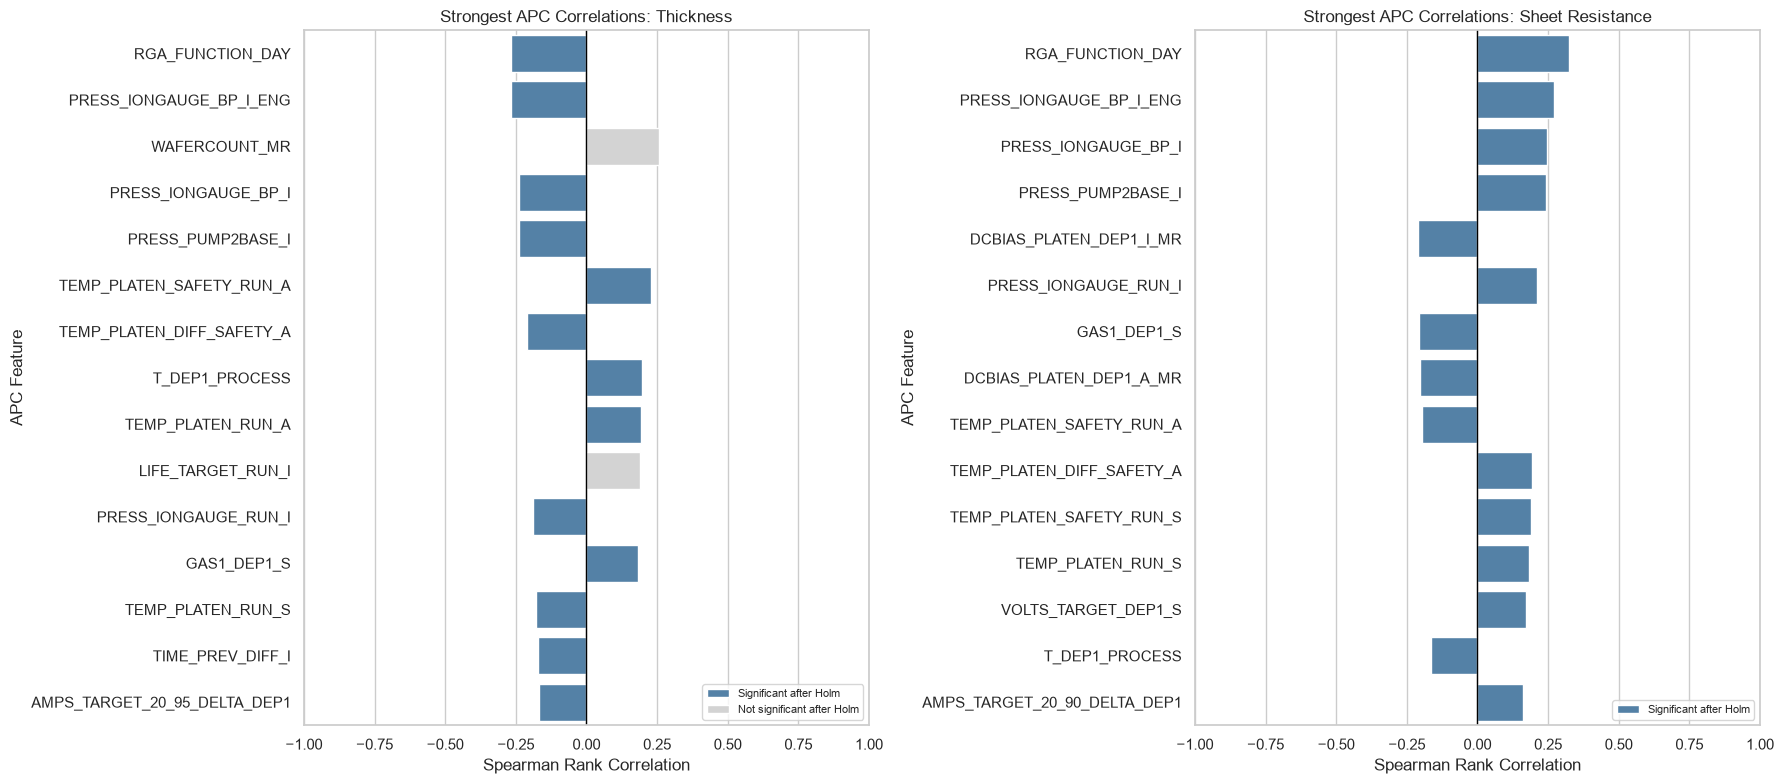

In [69]:

# Top sensor correlations for both material properties

fig, axes = plt.subplots(
    1,
    2,
    figsize=(18, 8),
)

for ax, target, label in [
    (
        axes[0],
        "mean_thickness",
        "Thickness",
    ),
    (
        axes[1],
        "mean_resistance",
        "Sheet Resistance",
    ),
]:

    plot_data = (
        correlation_results_df.loc[
            correlation_results_df["Target"]
            == target
        ]
        .sort_values(
            "Absolute Rho",
            ascending=False,
        )
        .head(15)
        .copy()
    )

    plot_data["Significance"] = np.where(
        plot_data["Significant"],
        "Significant after Holm",
        "Not significant after Holm",
    )

    sns.barplot(
        data=plot_data,
        x="Spearman Rho",
        y="Feature",
        hue="Significance",
        dodge=False,
        palette={
            "Significant after Holm": "steelblue",
            "Not significant after Holm": "lightgrey",
        },
        ax=ax,
    )

    ax.axvline(
        0,
        color="black",
        linewidth=1,
    )

    ax.set_xlim(-1, 1)

    ax.set_title(
        f"Strongest APC Correlations: {label}"
    )

    ax.set_xlabel("Spearman Rank Correlation")

    ax.set_ylabel("APC Feature")

    ax.legend(
        loc="lower right",
        fontsize=8,
    )

plt.tight_layout()
plt.show()

,Target,Correction,Significant Features
0,mean_thickness,Unadjusted,65
1,mean_thickness,Holm Adjusted,52
2,mean_resistance,Unadjusted,68
3,mean_resistance,Holm Adjusted,43


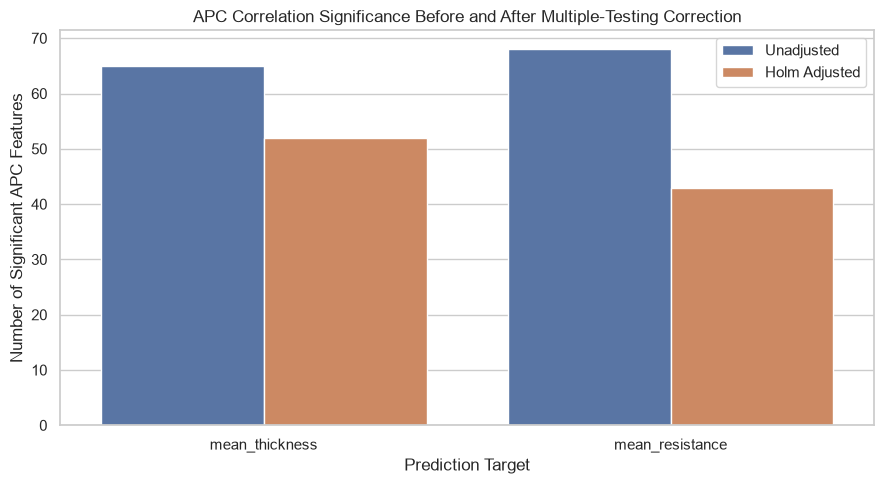

In [70]:

# Effect of multiple-testing correction

significance_comparison = []

for target in correlation_targets:

    subset = correlation_results_df.loc[
        correlation_results_df["Target"]
        == target
    ]

    significance_comparison.append({
        "Target": target,
        "Correction": "Unadjusted",
        "Significant Features": int(
            (subset["P-value"] < ALPHA).sum()
        ),
    })

    significance_comparison.append({
        "Target": target,
        "Correction": "Holm Adjusted",
        "Significant Features": int(
            subset["Significant"].sum()
        ),
    })

significance_comparison_df = pd.DataFrame(
    significance_comparison
)

display(significance_comparison_df)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=significance_comparison_df,
    x="Target",
    y="Significant Features",
    hue="Correction",
)

plt.title(
    "APC Correlation Significance Before "
    "and After Multiple-Testing Correction"
)

plt.xlabel("Prediction Target")
plt.ylabel("Number of Significant APC Features")

plt.legend()
plt.tight_layout()
plt.show()

## 10. Statistical Associations of Recurring ML Predictors

Investigate APC variables previously identified
through regression coefficients, impurity importance,
gain importance, and extrapolation diagnostics.

Compare their univariate statistical associations
with both virtual metrology targets.

Statistical association and multivariate model
importance measure different properties.

No feature-selection decision is made solely
from the observed p-values.

,Feature,Target,Records,Spearman Rho,P-value,Holm Adjusted P-value,Significant
13,T_DEP1_PROCESS,mean_resistance,1874,-0.165132,6.3297e-13,1.2280e-10,True
39,UTILISATION_TARGET_RUN_A,mean_resistance,1874,-0.095522,3.4456e-05,4.9748e-03,True
40,LIFE_TARGET_RUN_A,mean_resistance,1874,-0.095516,3.4494e-05,4.9748e-03,True
42,LIFE_TARGET_DEP1_A,mean_resistance,1874,-0.094968,3.8269e-05,5.3576e-03,True
56,LIFE_TARGET_DEP1_S,mean_resistance,1874,0.071412,1.9796e-03,2.2568e-01,False
115,T_DEP1_PROCESS,mean_thickness,1874,0.197572,6.0112e-18,1.2383e-15,True
137,LIFE_TARGET_RUN_A,mean_thickness,1874,0.121552,1.3058e-07,2.2067e-05,True
138,LIFE_TARGET_DEP1_A,mean_thickness,1874,0.121176,1.4283e-07,2.3996e-05,True
139,UTILISATION_TARGET_RUN_A,mean_thickness,1874,0.120896,1.5266e-07,2.5495e-05,True
154,LIFE_TARGET_DEP1_S,mean_thickness,1874,-0.095580,3.4074e-05,4.9748e-03,True


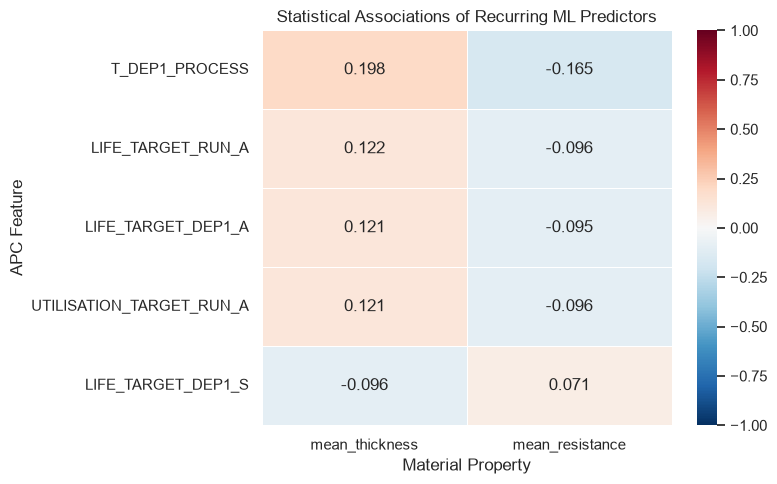

In [71]:

# Compare recurring ML predictors

recurring_features = [
    "T_DEP1_PROCESS",
    "LIFE_TARGET_RUN_A",
    "LIFE_TARGET_DEP1_A",
    "UTILISATION_TARGET_RUN_A",
    "LIFE_TARGET_DEP1_S",
]

recurring_feature_results = (
    correlation_results_df.loc[
        correlation_results_df["Feature"]
        .isin(recurring_features)
    ]
    .copy()
)

formatted_recurring = recurring_feature_results[
    [
        "Feature",
        "Target",
        "Records",
        "Spearman Rho",
        "P-value",
        "Holm Adjusted P-value",
        "Significant",
    ]
].copy()

formatting = {
    "Spearman Rho": "{:.6f}",
    "P-value": "{:.4e}",
    "Holm Adjusted P-value": "{:.4e}",
}

for column, fmt in formatting.items():
    formatted_recurring[column] = (
        formatted_recurring[column].map(fmt.format)
    )

display(formatted_recurring)

recurring_correlation_pivot = (
    recurring_feature_results.pivot(
        index="Feature",
        columns="Target",
        values="Spearman Rho",
    )
    .reindex(
        index=recurring_features,
        columns=correlation_targets,
    )
)

plt.figure(figsize=(8, 5))

sns.heatmap(
    recurring_correlation_pivot,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)

plt.title(
    "Statistical Associations of Recurring ML Predictors"
)

plt.xlabel("Material Property")
plt.ylabel("APC Feature")

plt.tight_layout()
plt.show()

## 11. Representative-Sample Sensitivity Analysis

Compare observed statistical effect sizes across
three analysis populations:

1. All original training wafer observations.
2. Earliest eligible training wafer per lot.
3. Latest eligible training wafer per lot.

Investigate whether the representative-selection
procedure materially changes the observed effects.

The populations overlap and are not independent.

Report effect sizes rather than conducting
additional significance decisions.

In [72]:

# Representative-selection sensitivity analysis

latest_lot_analysis_df = (
    analysis_df
    .drop_duplicates(
        subset="lot",
        keep="last",
    )
    .reset_index(drop=True)
)

assert latest_lot_analysis_df["lot"].is_unique

assert len(latest_lot_analysis_df) == (
    len(lot_analysis_df)
)

sensitivity_populations = {
    "Full Training": analysis_df,
    "Earliest per Lot": lot_analysis_df,
    "Latest per Lot": latest_lot_analysis_df,
}

sensitivity_results = []

for population_name, population in (
    sensitivity_populations.items()
):

    for hypothesis_id, predictor in [
        ("H1", "equipment"),
        ("H2", "stable_state"),
    ]:

        contingency = pd.crosstab(
            population[predictor],
            population["Overall Quality"],
        )

        sensitivity_results.append({
            "Population": population_name,
            "Hypothesis": hypothesis_id,
            "Records": int(
                contingency.to_numpy().sum()
            ),
            "Effect Size Name": "Cramer's V",
            "Effect Size": calculate_cramers_v(
                contingency
            ),
        })

    for hypothesis_id, target in [
        ("H3a", "mean_thickness"),
        ("H3b", "mean_resistance"),
    ]:

        result = equipment_kruskal_test(
            data=population,
            target=target,
            hypothesis_id=hypothesis_id,
        )

        sensitivity_results.append({
            "Population": population_name,
            "Hypothesis": hypothesis_id,
            "Records": result["Records"],
            "Effect Size Name": result[
                "Effect Size Name"
            ],
            "Effect Size": result["Effect Size"],
        })

    for hypothesis_id, target in [
        ("H4a", "mean_thickness"),
        ("H4b", "mean_resistance"),
    ]:

        result = quality_mannwhitney_test(
            data=population,
            target=target,
            hypothesis_id=hypothesis_id,
        )

        sensitivity_results.append({
            "Population": population_name,
            "Hypothesis": hypothesis_id,
            "Records": result["Records"],
            "Effect Size Name": result[
                "Effect Size Name"
            ],
            "Effect Size": result["Effect Size"],
        })

sensitivity_df = pd.DataFrame(
    sensitivity_results
)

sensitivity_comparison = (
    sensitivity_df.pivot(
        index=[
            "Hypothesis",
            "Effect Size Name",
        ],
        columns="Population",
        values="Effect Size",
    )
)

display(
    sensitivity_comparison.round(6)
)

,Population,Earliest per Lot,Full Training,Latest per Lot
Hypothesis,Effect Size Name,,,
H1,Cramer's V,0.175507,0.133254,0.152609
H2,Cramer's V,0.029119,0.032589,0.034886
H3a,Rank-based epsilon-squared,0.094474,0.055613,0.096955
H3b,Rank-based epsilon-squared,0.077983,0.052011,0.088507
H4a,Rank-biserial correlation,0.069947,-0.084124,-0.138702
H4b,Rank-biserial correlation,-0.319459,-0.206136,-0.141302


## 12. Final Statistical Interpretation

Generate a consolidated interpretation of the
primary hypothesis decisions.

Distinguish statistical significance, effect
magnitude, and practical engineering relevance.

Summarise the corrected APC correlation results.

All findings remain exploratory and subject to
the stated statistical assumptions.

In [73]:

# Generate interpretable hypothesis summaries

hypothesis_descriptions = {
    "H1": (
        "Equipment identity and overall quality"
    ),
    "H2": (
        "Process stability and overall quality"
    ),
    "H3a": (
        "Thickness distributions across equipment"
    ),
    "H3b": (
        "Resistance distributions across equipment"
    ),
    "H4a": (
        "Thickness distributions by overall quality"
    ),
    "H4b": (
        "Resistance distributions by overall quality"
    ),
}

print("=" * 65)
print("STRATUM - PRIMARY STATISTICAL FINDINGS")
print("=" * 65)

for _, row in primary_results_df.iterrows():

    hypothesis_id = row["Hypothesis"]

    print(
        f"\n{hypothesis_id}: "
        f"{hypothesis_descriptions[hypothesis_id]}"
    )

    print(f"Test: {row['Test']}")

    print(f"Records: {row['Records']}")

    print(
        f"Raw p-value: "
        f"{row['P-value']:.6e}"
    )

    print(
        f"Holm-adjusted p-value: "
        f"{row['Holm Adjusted P-value']:.6e}"
    )

    print(
        f"{row['Effect Size Name']}: "
        f"{row['Effect Size']:.6f}"
    )

    if row["Significant"]:

        print(
            "Decision: Reject the null hypothesis."
        )

        print(
            "Interpretation: Statistical evidence "
            "against the null hypothesis under "
            "the stated assumptions."
        )

    else:

        print(
            "Decision: Fail to reject "
            "the null hypothesis."
        )

        print(
            "Interpretation: Insufficient statistical "
            "evidence against the null hypothesis."
        )

print("\n" + "=" * 65)
print("APC CORRELATION FINDINGS")
print("=" * 65)

for target in correlation_targets:

    subset = correlation_results_df.loc[
        correlation_results_df["Target"] == target
    ]

    significant = subset.loc[
        subset["Significant"]
    ]

    print(f"\nTarget: {target}")

    print("Tested features:", len(subset))

    print(
        "Statistically significant features:",
        len(significant)
    )

    if not significant.empty:

        strongest = (
            significant
            .sort_values(
                "Absolute Rho",
                ascending=False,
            )
            .iloc[0]
        )

        print(
            "Strongest significant feature:",
            strongest["Feature"]
        )

        print(
            "Spearman rho:",
            round(
                strongest["Spearman Rho"],
                6,
            )
        )

print("\nInterpretation limitation:")

print(
    "Statistical association does not establish "
    "causality or practical process significance."
)

STRATUM - PRIMARY STATISTICAL FINDINGS

H1: Equipment identity and overall quality
Test: Pearson Chi-square
Records: 1874
Raw p-value: 6.180639e-07
Holm-adjusted p-value: 1.854192e-06
Cramer's V: 0.175507
Decision: Reject the null hypothesis.
Interpretation: Statistical evidence against the null hypothesis under the stated assumptions.

H2: Process stability and overall quality
Test: Pearson Chi-square
Records: 1874
Raw p-value: 2.074694e-01
Holm-adjusted p-value: 2.768983e-01
Cramer's V: 0.029119
Decision: Fail to reject the null hypothesis.
Interpretation: Insufficient statistical evidence against the null hypothesis.

H3a: Thickness distributions across equipment
Test: Kruskal-Wallis
Records: 1874
Raw p-value: 1.768130e-32
Holm-adjusted p-value: 1.060878e-31
Rank-based epsilon-squared: 0.094474
Decision: Reject the null hypothesis.
Interpretation: Statistical evidence against the null hypothesis under the stated assumptions.

H3b: Resistance distributions across equipment
Test: Krus

## 13. Statistical Experiment Result Preservation

Preserve the statistical analysis population,
hypothesis test results, corrected p-values,
effect sizes, sensor correlation results,
and sensitivity analysis.

Record dataset fingerprint, software version,
statistical assumptions, and correction methods.

Do not export individual wafer measurements
or evaluate reserved test targets.

In [74]:

# Save statistical research results

def dataframe_to_json_records(frame):

    # Convert NumPy types and missing values into
    # standard JSON-compatible representations.

    return json.loads(
        frame.to_json(
            orient="records",
            double_precision=15,
        )
    )


results_dir = (
    project_root / "ml" / "results"
)

results_dir.mkdir(
    parents=True,
    exist_ok=True,
)

results_path = (
    results_dir
    / "statistical_significance.json"
)

statistical_experiment = {
    "project": "STRATUM",

    "experiment": (
        "statistical_significance_testing"
    ),

    "dataset_sha256": current_sha256,

    "analysis_partition": "training",

    "training_records": len(train_df),

    "representative_records": len(
        lot_analysis_df
    ),

    "representative_selection": (
        "Earliest chronological training wafer per lot, "
        "with wafer identifier as tie-breaker"
    ),

    "unique_representative_lots": int(
        lot_analysis_df["lot"].nunique()
    ),

    "significance_level": ALPHA,

    "multiple_testing_correction": "Holm",

    "primary_hypothesis_count": len(
        primary_results_df
    ),

    "significant_primary_hypotheses": int(
        primary_results_df["Significant"].sum()
    ),

    "correlation_candidate_pairs": (
        len(apc_features)
        * len(correlation_targets)
    ),

    "correlation_tested_pairs": len(
        correlation_results_df
    ),

    "correlation_significant_pairs": int(
        correlation_results_df["Significant"].sum()
    ),

    "minimum_correlation_records": (
        MIN_CORRELATION_RECORDS
    ),

    "monte_carlo_simulations": N_MONTE_CARLO,

    "random_state": RANDOM_STATE,

    "scipy_version": scipy.__version__,

    "population_summary": (
        dataframe_to_json_records(
            population_summary
        )
    ),

    "batch_dependence": {
        "unique_batches": len(
            batch_dependency_summary
        ),

        "batches_with_multiple_lots": len(
            shared_batches
        ),

        "missing_batch_identifiers": int(
            lot_analysis_df["bat_id"].isna().sum()
        ),
    },

    "primary_hypothesis_results": (
        dataframe_to_json_records(
            primary_results_df
        )
    ),

    "equipment_quality_rates": (
        dataframe_to_json_records(
            equipment_quality_rates.reset_index()
        )
    ),

    "stability_quality_rates": (
        dataframe_to_json_records(
            stability_quality_rates.reset_index()
        )
    ),

    "equipment_material_summary": (
        dataframe_to_json_records(
            equipment_material_summary.reset_index()
        )
    ),

    "correlation_summary": (
        dataframe_to_json_records(
            correlation_summary.reset_index()
        )
    ),

    "correlation_results": (
        dataframe_to_json_records(
            correlation_results_df
        )
    ),

    "skipped_correlations": (
        dataframe_to_json_records(
            skipped_correlations_df
        )
    ),

    "recurring_feature_results": (
        dataframe_to_json_records(
            recurring_feature_results
        )
    ),

    "sensitivity_results": (
        dataframe_to_json_records(
            sensitivity_df
        )
    ),

    "limitations": [
        "Hypotheses informed by prior exploratory analysis.",
        "Representative sampling reduces but does not "
        "eliminate observation dependence.",
        "Potential equipment, batch and temporal dependence.",
        "Complete-case correlations may be affected "
        "by non-random missingness.",
        "Spearman p-values use analytical approximations.",
        "Overall quality is derived from material-property "
        "quality classifications.",
        "Statistical association does not establish causality.",
        "No official engineering acceptance thresholds.",
        "Final test partition not evaluated in this experiment.",
    ],
}

with open(
    results_path,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        statistical_experiment,
        file,
        indent=4,
        allow_nan=False,
    )

print("Statistical experiment results saved.")

print(
    "ml/results/statistical_significance.json"
)

Statistical experiment results saved.
ml/results/statistical_significance.json


## 14. Statistical Analysis Integrity Verification

Verify representative sample uniqueness,
partition separation, statistical result ranges,
multiple-testing correction, and experiment
result preservation.

These checks establish implementation integrity
rather than proving all statistical assumptions.

In [75]:

# Verify statistical experiment integrity

assert lot_analysis_df["lot"].is_unique

assert set(
    lot_analysis_df["wafer_id"]
).issubset(
    set(train_df["wafer_id"])
)

assert set(
    lot_analysis_df["lot"]
).isdisjoint(
    set(val_df["lot"])
)

assert set(
    lot_analysis_df["lot"]
).isdisjoint(
    set(test_df["lot"])
)

assert len(primary_results_df) == 6

assert primary_results_df[
    "Hypothesis"
].is_unique

# Verify p-value ranges and Holm correction

for result_df in [
    primary_results_df,
    correlation_results_df,
]:

    assert np.isfinite(
        result_df["P-value"]
    ).all()

    assert result_df[
        "P-value"
    ].between(0, 1).all()

    assert result_df[
        "Holm Adjusted P-value"
    ].between(0, 1).all()

    assert (
        result_df["Holm Adjusted P-value"]
        >= result_df["P-value"] - 1e-15
    ).all()

    assert np.array_equal(
        result_df["Significant"].to_numpy(),
        (
            result_df["Holm Adjusted P-value"]
            < ALPHA
        ).to_numpy(),
    )

assert correlation_results_df[
    "Spearman Rho"
].between(-1, 1).all()

assert (
    correlation_results_df["Records"]
    >= MIN_CORRELATION_RECORDS
).all()

assert (
    len(correlation_results_df)
    + len(skipped_correlations_df)
    == len(apc_features)
    * len(correlation_targets)
)

# Verify saved JSON

saved_results = json.loads(
    results_path.read_text(encoding="utf-8")
)

assert (
    saved_results["dataset_sha256"]
    == current_sha256
)

assert (
    saved_results["analysis_partition"]
    == "training"
)

assert (
    saved_results["primary_hypothesis_count"]
    == len(primary_results_df)
)

assert (
    saved_results["correlation_tested_pairs"]
    == len(correlation_results_df)
)

print("Statistical analysis integrity: PASSED")

print(
    "Primary hypotheses verified:",
    len(primary_results_df)
)

print(
    "Sensor-target tests verified:",
    len(correlation_results_df)
)

print("Final test targets not evaluated.")

print("Experiment JSON verification: PASSED")

Statistical analysis integrity: PASSED
Primary hypotheses verified: 6
Sensor-target tests verified: 216
Final test targets not evaluated.
Experiment JSON verification: PASSED



## 15. Findings and Engineering Interpretation

### Statistical Analysis Population

- Original training observations: 3331.
- Representative observations per lot: [record result].
- Unique represented equipment groups: [record result].
- Representative bad-quality percentage: [record result].
- Batches with multiple represented lots: [record result].

One chronological representative wafer per lot
was selected to reduce within-lot dependence.

Potential dependence across manufacturing batches,
equipment, and time remains a limitation.

### Equipment and Overall Quality

- Selected statistical test:
- Test statistic:
- Raw p-value:
- Holm-adjusted p-value:
- Cramer's V:
- Hypothesis decision:

Discuss the observed association and its magnitude.

An association does not establish that particular
equipment units are defective.

### Process Stability and Overall Quality

- Selected statistical test:
- Test statistic:
- Raw p-value:
- Holm-adjusted p-value:
- Cramer's V:
- Hypothesis decision:

Discuss whether the dataset-defined stability
indicator is associated with overall wafer quality.

### Material Properties Across Equipment

Thickness:

- Kruskal-Wallis H statistic:
- Holm-adjusted p-value:
- Rank-based epsilon-squared:
- Hypothesis decision:

Sheet resistance:

- Kruskal-Wallis H statistic:
- Holm-adjusted p-value:
- Rank-based epsilon-squared:
- Hypothesis decision:

Discuss observed equipment-level distribution
differences without attributing physical causality.

### Material Properties and Overall Quality

Thickness:

- Mann-Whitney U statistic:
- Holm-adjusted p-value:
- Rank-biserial correlation:
- Hypothesis decision:

Sheet resistance:

- Mann-Whitney U statistic:
- Holm-adjusted p-value:
- Rank-biserial correlation:
- Hypothesis decision:

Overall quality is derived from related
material-property quality classifications.

The results characterise dataset relationships
rather than independently validating prospective
quality prediction.

### APC Correlation Significance

- Candidate sensor-target pairs: 220.
- Successfully tested pairs:
- Skipped pairs:
- Significant before correction:
- Significant after Holm correction:
- Significant thickness-related features:
- Significant resistance-related features:
- Strongest significant thickness association:
- Strongest significant resistance association:

Discuss the strongest observed correlations
alongside complete-case sample sizes.

### Recurring ML Predictors

Compare the statistical associations of important
features previously identified through Ridge,
Random Forest, and XGBoost.

Univariate correlation and multivariate feature
importance measure different aspects of the data.

No sensor is automatically excluded from ML
based only on its statistical significance.

### Representative-Sample Sensitivity

Compare effect sizes using:

- Full training population.
- Earliest wafer per lot.
- Latest wafer per lot.

Record whether the observed effects remain
reasonably consistent across populations.

### Multiple-Testing Correction

Holm correction was applied separately to:

1. The six primary hypothesis tests.
2. All successfully tested APC sensor-target pairs.

Final significance decisions use adjusted p-values
at alpha = 0.05.

### Implications for STRATUM

The investigation provides statistical context for:

- Equipment-level quality monitoring.
- Multi-parameter material-property analysis.
- Sensor relationship interpretation.
- Explainable virtual metrology.
- Evidence-grounded engineering reports.

Statistical findings complement, rather than replace,
chronological predictive model evaluation.

### Limitations

- Hypotheses were informed by prior EDA.
- Findings are exploratory.
- Representative sampling does not guarantee
  complete independence.
- Batch, equipment, and temporal dependence remain.
- Complete-case correlations may be selection-biased.
- Statistical significance does not imply
  engineering importance or causality.
- Quality labels are derived from related
  material-property classifications.
- Official physical acceptance thresholds
  are unavailable.
- The final test partition has not been evaluated.

### Conclusion

This supplementary investigation strengthens
the statistical research foundation of STRATUM.

Formal hypothesis testing, assumption checks,
effect-size analysis, and multiple-testing correction
extend the previous descriptive EDA methodology.

The next stage investigates chronological
cross-validation and hyperparameter optimisation
of the candidate virtual metrology models.